In [1]:
import hill_climbing as hc
import matplotlib.pyplot as plt
import json


In [2]:
with open("../data/packages.json") as f:
    packages = json.load(f)
with open("../data/truck.json") as f:
    truck = json.load(f)


In [3]:
rows = []

for variant, params in hc.CONFIGS:
    for x in (1, 2, 3):
        r = hc.Run(variant, packages, truck, seed=x, **params)
        hc.saveRun(r, packages, truck, f"../../output/hill_climbing/{variant}/run{x}")
        rows.append(hc.summaryRow(r))
        print(f"{variant} run {x}: final {r['finalVal']}, {r['duration']:.2f} s, iterasi {r['iterations']}")

hc.saveSummary(rows, "../../output/hill_climbing/summary.json")


steepest_ascent run 1: final 2035, 0.04 s, iterasi 13


steepest_ascent run 2: final 2140, 0.12 s, iterasi 12


steepest_ascent run 3: final 1815, 0.14 s, iterasi 6


stochastic run 1: final 1550, 0.30 s, iterasi 15


stochastic run 2: final 1610, 0.20 s, iterasi 6


...

sideways_move run 2: final 2140, 7.68 s, iterasi 212


sideways_move run 3: final 1815, 6.11 s, iterasi 206


random_restart run 1: final 2150, 2.17 s, iterasi 171


random_restart run 2: final 2250, 2.18 s, iterasi 180


random_restart run 3: final 2250, 2.04 s, iterasi 183


In [4]:
for x in (1, 2, 3):
    r = hc.Run("steepest_ascent", packages, truck, seed=x, objective="urgency")
    hc.saveRun(r, packages, truck, f"../../output/hill_climbing/bonus_alt_objective/steepest/run{x}")
    base = next(row for row in rows if row["variant"] == "steepest_ascent" and row["seed"] == x)
    print(f"seed {x}: value {base['realValue']} vs urgency {r['realValue']} (skor {r['finalVal']:.2f})")


seed 1: value 2035 vs urgency 1975 (skor 1319.42)


seed 2: value 2140 vs urgency 2010 (skor 1049.42)


seed 3: value 1815 vs urgency 1975 (skor 1096.92)


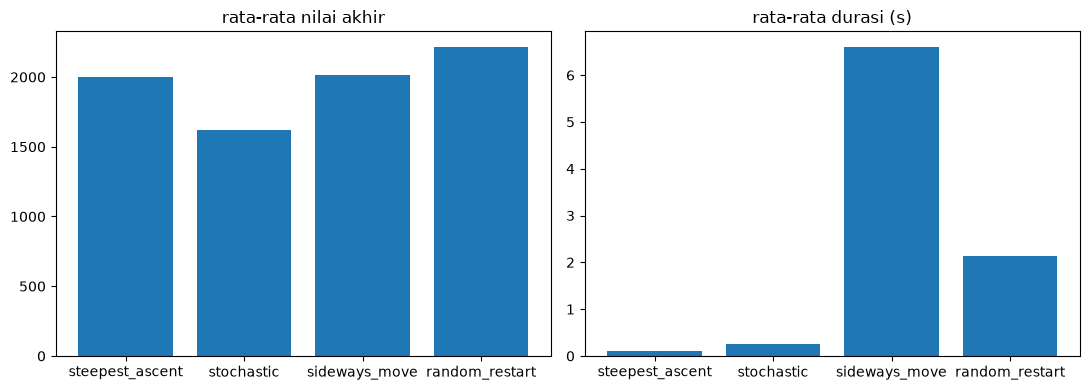

In [5]:
variants = [variant for variant, _ in hc.CONFIGS]
means = [sum(row["finalValue"] for row in rows if row["variant"] == v) / 3 for v in variants]
durations = [sum(row["duration"] for row in rows if row["variant"] == v) / 3 for v in variants]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.bar(variants, means)
ax1.set_title("rata-rata nilai akhir")
ax2.bar(variants, durations)
ax2.set_title("rata-rata durasi (s)")
plt.tight_layout()
plt.savefig("../../output/hill_climbing/plotSummary.png", dpi=100)
